<a id="topo"></a>

# Hemodiálise e internações por insuficiência renal no SUS

**Exploração de padrões territoriais e temporais em 2024–2025 com metodologias estatísticas**

*Trabalho final da disciplina de Estatística Aplicada à Análise de Dados.*

Este estudo utiliza registros públicos do Sistema Único de Saúde (SUS) para investigar como a produção aprovada de hemodiálise e as internações por insuficiência renal se distribuem entre as Unidades da Federação e como variaram entre 2024 e 2025. A proposta é **explorar os dados e identificar padrões territoriais e temporais por meio da aplicação de metodologias estatísticas**. Busca-se investigar tendências, oscilações mensais, contrastes entre UFs e regiões e possíveis associações entre os indicadores, transformando essas observações em respostas fundamentadas, com cálculos reproduzíveis e interpretação dos resultados.

A análise reúne dados do SIA/SUS, do SIH/TabNet e estimativas populacionais do IBGE. O painel compreende **27 UFs e 24 meses**, totalizando **648 combinações UF-mês**. As mudanças entre os anos são comparadas na janela comum de **janeiro a outubro**; a série mensal SIA de 24 meses é utilizada na avaliação retrospectiva de modelos simples de previsão.

**Como ler este trabalho**

O notebook está organizado pela metodologia aplicada. Cada etapa relaciona a pergunta de análise ao procedimento utilizado, às saídas do código e à interpretação dos resultados. O estudo de probabilidades apresenta cinco exemplos completos; os testes e a modelagem preditiva complementam a descrição territorial.

**Sumário**

1. [Introdução, contexto e problema](#secao-1)
2. [Objetivos e delimitação do estudo](#secao-2)
3. [Preparação do ambiente e leitura da base](#secao-3)
4. [Controle de qualidade e cobertura](#secao-4)
5. [Sensibilidade por imputação sazonal](#secao-5)
6. [Estatística descritiva e análise territorial](#secao-6)
7. [Probabilidades simples e compostas](#secao-7)
8. [Inferência: sinais, Spearman, Holm e comparação regional](#secao-8)
9. [Modelagem preditiva e validação temporal](#secao-9)
10. [Discussão, conclusão e limitações](#secao-10)
11. [Reprodutibilidade e exportação](#secao-11)
12. [Referências bibliográficas e fontes](#secao-12)

Na seção 7, cada probabilidade mantém pergunta, fórmula, cálculo, saída e interpretação. Execute as células do início ao fim para reproduzir o trabalho.

<a id="secao-1"></a>

## 1. Introdução, contexto e problema de pesquisa

### 1.1 Contexto do estudo

Os sistemas de informação do SUS registram atividades assistenciais que podem ser analisadas por território e período. Neste trabalho, o **SIA/SUS** informa a quantidade aprovada de procedimentos de hemodiálise, enquanto o **SIH/TabNet** informa internações na categoria diagnóstica de insuficiência renal. As estimativas anuais de população do **IBGE** permitem contextualizar os volumes de produção em territórios de tamanhos diferentes.

Essas fontes descrevem dimensões distintas do registro administrativo. A produção ambulatorial não identifica, por si só, quantas pessoas foram atendidas; as internações também não equivalem a pacientes únicos. Por isso, os dois indicadores são analisados separadamente e suas associações são interpretadas no nível territorial.

### 1.2 Delimitação do tema

O recorte hospitalar utilizado é **N17–N19**, que reúne insuficiência renal aguda, crônica e não especificada. Embora o projeto tenha se originado no tema da doença renal crônica e mantenha a sigla DRC no nome do arquivo, o indicador hospitalar disponível **não é específico de DRC**. O objeto efetivamente estudado é a produção registrada de hemodiálise e as internações por insuficiência renal no SUS.

A unidade integrada é **UF-mês**. Na comparação entre anos, os valores de janeiro–outubro são somados por UF, formando 27 pares territoriais. Essa escolha preserva períodos equivalentes e exclui das comparações principais os meses finais de 2025 com dúvida de completude SIH.

### 1.3 Problema de pesquisa

**Quais padrões de distribuição, variação temporal e associação territorial podem ser identificados na produção aprovada de hemodiálise e nas internações por insuficiência renal no SUS, a partir dos dados disponíveis de 2024 e 2025 e da aplicação de metodologias estatísticas?**

A investigação procura reconhecer onde os indicadores se concentram, como evoluem ao longo dos meses, se as mudanças entre anos são disseminadas ou heterogêneas e se as variações dos dois sistemas se acompanham entre UFs. Valores extremos e contrastes territoriais são pontos de exploração, cuja leitura considera o tamanho das bases e a qualidade dos registros.

Identificar um padrão envolve descrever sua magnitude e sua distribuição e examinar o apoio oferecido pelo método empregado. A interpretação considera que valores ausentes, atualização dos registros e diferenças entre fontes também podem produzir contrastes aparentes.

### 1.4 Contribuição estatística e acadêmica

O trabalho aplica controle de qualidade, estatística descritiva, indicadores populacionais anuais, probabilidades empíricas, testes de hipóteses, correlação e validação temporal de modelos. O percurso articula **exploração, identificação de padrões e interpretação estatística**: as tabelas e os gráficos orientam a observação das distribuições e oscilações; as probabilidades quantificam a frequência territorial de eventos; os testes e a correlação examinam evidências de padrões direcionais, regionais e associativos; e a validação temporal avalia a capacidade de regras simples anteciparem valores da série SIA.

Os padrões encontrados podem orientar hipóteses para estudos futuros. Como a análise é exploratória e utiliza uma única extração, sua identificação e sua avaliação no mesmo conjunto de dados não constituem confirmação independente. A série de 24 meses também limita conclusões sobre persistência de tendências e sazonalidade.

As respostas são **descritivas, ecológicas e exploratórias**. O estudo não estima prevalência de DRC, acesso individual, efetividade terapêutica ou causalidade. A documentação das fontes e a bibliografia estão reunidas na [seção 12 — Referências](#secao-12).

<a id="secao-2"></a>

## 2. Objetivos, perguntas de análise e alcance

### 2.1 Objetivo geral

Explorar os registros de produção aprovada de hemodiálise e de internações N17–N19 no SUS para identificar e caracterizar padrões territoriais e temporais em 2024–2025, aplicando estatística descritiva, probabilidades, testes de hipóteses, correlação e modelagem preditiva exploratória. A análise quantifica mudanças em períodos comparáveis, examina contrastes e associações entre UFs e avalia retrospectivamente previsões de um mês à frente da série SIA.

### 2.2 Objetivos específicos e perguntas correspondentes

| Objetivo | Pergunta respondida | Metodologia principal |
|---|---|---|
| Verificar a qualidade do painel | Qual é a cobertura e onde há dados ausentes? | Validação de chaves, contagens e cobertura. |
| Descrever volumes e contrastes | Quanto foi registrado e como se distribuiu entre territórios? | Medidas descritivas, gráficos e produção anual por população. |
| Explorar a evolução mensal | Quais tendências e oscilações aparecem nos totais mensais disponíveis? | Inspeção descritiva das séries e dos gráficos, considerando a cobertura. |
| Quantificar mudanças | Quanto cada indicador aumentou ou diminuiu entre períodos equivalentes? | Comparação pareada por UF; diferenças absolutas e percentuais. |
| Aplicar probabilidade | Com que frequência uma UF apresentou aumento isolado, conjunto ou redução dos indicadores? | Probabilidades empíricas, interseção e união de eventos. |
| Explorar padrões territoriais | Há evidência de mudança direcional, associação entre variações ou diferença regional? | Teste de sinais, Spearman, Holm e comparação regional. |
| Comparar previsões simples | Qual regra apresentou menor erro ao antecipar um mês da série SIA em 2025? | Validação de origem móvel e comparação de MAE, RMSE e MAPE. |

### 2.3 Alcance das respostas

Cada linha do painel representa uma UF-mês; os testes estaduais utilizam 27 UFs e a modelagem utiliza 24 totais nacionais mensais. Não há vínculo individual entre SIA e SIH. As proporções descrevem o conjunto observado, os testes são apoio exploratório e o cenário de 2026 é uma extrapolação didática a partir de dezembro/2025, sem uso operacional.

<a id="secao-3"></a>

## 3. Preparação do ambiente e leitura da base

A paleta mantém SIA em azul, SIH em laranja e resultados de apoio em verde.

**Objetivo:** carregar o painel e preparar as ferramentas de análise.

**Procedimento:** importar bibliotecas, localizar o CSV, interpretar datas e conferir número de linhas, duplicação das chaves e valores não negativos.

**Unidade de análise:** UF-mês; a dimensão populacional é anual. A saída seguinte informa a cobertura estrutural da base.

In [1]:
from pathlib import Path
from math import sqrt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

sns.set_theme(style='whitegrid', context='notebook')
CORES = {'sia': '#1F5A99', 'sih': '#E07A32', 'destaque': '#2A9D8F', 'alerta': '#C44536', 'cinza': '#5B6470'}
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

candidatos = [Path.cwd() / 'Trabalho-final', Path.cwd(), Path.cwd().parent]
projeto = next(c.resolve() for c in candidatos if (c / 'Dados').is_dir())
arquivo_base = projeto / 'Dados/03_bases_analiticas/descritiva_territorial_2024_2025/painel_descritivo_uf_mes_2024_2025.csv'

painel = pd.read_csv(arquivo_base, sep=';', encoding='utf-8-sig')
painel['data'] = pd.to_datetime(painel['competencia'] + '-01')
painel['mes_nome'] = pd.Categorical(painel['mes'].map(dict(enumerate(MESES, start=1))), categories=MESES, ordered=True)

assert painel.shape[0] == 648
assert painel[['cod_uf', 'ano', 'mes']].duplicated().sum() == 0
assert painel['sia_hemodialise_quantidade_aprovada'].ge(0).all(), (
    'sia_hemodialise_quantidade_aprovada deve conter apenas valores não negativos.'
)
assert painel['sih_n17_n19_internacoes_tabnet'].dropna().ge(0).all(), (
    'sih_n17_n19_internacoes_tabnet deve conter apenas valores observados não negativos.'
)
print(f'Base carregada: {painel.shape[0]} linhas UF-mês, {painel.sigla_uf.nunique()} UFs e {painel.data.nunique()} competências.')

Matplotlib is building the font cache; this may take a moment.


Base carregada: 648 linhas UF-mês, 27 UFs e 24 competências.


<a id="secao-4"></a>

## 4. Controle de qualidade e cobertura dos dados

Na leitura da base, a quantidade aprovada SIA e as internações observadas SIH são verificadas para garantir valores não negativos.

A ausência SIH é tratada como ausente, nunca como zero. A janela principal usa janeiro–outubro para evitar a possível incompletude do SIH em novembro/dezembro de 2025.

### 4.1 Diagnóstico de cobertura e dados ausentes

**Método:** contagem de células SIH preenchidas por competência e comparação com as UFs esperadas.

**Leitura do resultado:** uma célula preenchida indica presença de registro, sem comprovar maturidade administrativa. Dezembro/2025 contém 26 UFs observadas; RR permanece ausente.

In [2]:
cobertura = (painel.assign(sih_observado=painel['sih_n17_n19_internacoes_tabnet'].notna())
            .groupby(['ano', 'mes'], as_index=False)
            .agg(ufs_sih_observadas=('sih_observado', 'sum'), ufs_esperadas=('sigla_uf', 'nunique')))
cobertura['cobertura_sih_pct'] = 100 * cobertura['ufs_sih_observadas'] / cobertura['ufs_esperadas']

display(cobertura.tail(6))
print('Células SIH ausentes:', painel.loc[painel['sih_n17_n19_internacoes_tabnet'].isna(), ['sigla_uf', 'competencia']].to_dict('records'))

,ano,mes,ufs_sih_observadas,ufs_esperadas,cobertura_sih_pct
18,2025,7,27,27,100.000000
19,2025,8,27,27,100.000000
20,2025,9,27,27,100.000000
21,2025,10,27,27,100.000000
22,2025,11,27,27,100.000000
23,2025,12,26,27,96.296296


Células SIH ausentes: [{'sigla_uf': 'RR', 'competencia': '2025-12'}]


### 4.2 Seleção de variáveis e critérios de exclusão

| Campo | Uso na análise | Decisão e justificativa |
|---|---|---|
| `sia_hemodialise_quantidade_aprovada` | Descrição, probabilidade, inferência e previsão | Mantido: é o indicador de produção ambulatorial disponível e completo. |
| `sih_n17_n19_internacoes_tabnet` | Descrição, probabilidade e inferência | Mantido observado; imputação só em sensibilidade. Excluído da previsão por possível incompletude em nov/dez 2025. |
| `populacao_ibge_referencia_anual` | Denominador para taxa ecológica por 100 mil | Mantido somente em agregações anuais; a referência é julho, não mensal. |
| `regiao`, `ano`, `mes`, `competencia` | Estratificação, comparação e eixo temporal | Mantidos: definem o contexto territorial e temporal. |
| `cod_uf`, `sigla_uf`, `uf` | Chave e rótulo | Não entram como preditores: identificam a observação, sem significado numérico. |
| N18 e APAC | Fora do painel final | Excluídos: auditorias pendentes e ausência de vínculo individual válido. |

<a id="secao-5"></a>

## 5. Análise de sensibilidade — imputação sazonal ajustada

Há uma única ausência: internações SIH de Roraima em dezembro de 2025. A base original é preservada; cria-se apenas uma cópia analítica.

O método usa o valor de dezembro de 2024 da mesma UF, ajustado pela razão entre os totais observados de janeiro–outubro de 2025 e 2024 em Roraima. A janela evita novembro, cuja maturidade está em verificação. A imputação é apenas uma sensibilidade; tabelas, gráficos e testes principais mantêm a ausência original.

**Objetivo:** avaliar o impacto da única ausência sob uma regra explícita, sem substituir a análise principal.

**Método:** dezembro/2024 de RR × razão dos totais RR janeiro–outubro de 2025 e 2024, com arredondamento inteiro.

**Interpretação esperada:** a saída mostra o valor imputado e o impacto na soma observada; não representa o valor real recuperado nem corrige a possível incompletude dos demais registros.

In [3]:
painel_analitico = painel.copy()
mascara_ausente = painel_analitico['sih_n17_n19_internacoes_tabnet'].isna()
assert mascara_ausente.sum() == 1

rr_2024 = painel.query("sigla_uf == 'RR' and ano == 2024 and mes <= 10")['sih_n17_n19_internacoes_tabnet'].sum()
rr_2025 = painel.query("sigla_uf == 'RR' and ano == 2025 and mes <= 10")['sih_n17_n19_internacoes_tabnet'].sum()
dezembro_rr_2024 = painel.query("sigla_uf == 'RR' and ano == 2024 and mes == 12")['sih_n17_n19_internacoes_tabnet'].iloc[0]
fator_crescimento_rr = rr_2025 / rr_2024
valor_imputado = int(round(dezembro_rr_2024 * fator_crescimento_rr))

painel_analitico['sih_origem'] = np.where(mascara_ausente, 'imputado_sazonal', 'observado')
painel_analitico.loc[mascara_ausente, 'sih_n17_n19_internacoes_tabnet'] = valor_imputado

registro_imputacao = painel_analitico.loc[mascara_ausente, ['sigla_uf', 'competencia', 'sih_n17_n19_internacoes_tabnet', 'sih_origem']].copy()
registro_imputacao['fator_crescimento_jan_out'] = fator_crescimento_rr
display(registro_imputacao.style.format({'fator_crescimento_jan_out': '{:.3f}'}))
impacto_sensibilidade = pd.DataFrame([{
    'total_SIH_2025_observado': painel.query('ano == 2025')['sih_n17_n19_internacoes_tabnet'].sum(),
    'total_SIH_2025_com_imputacao': painel_analitico.query('ano == 2025')['sih_n17_n19_internacoes_tabnet'].sum(),
}])
display(impacto_sensibilidade.style.format('{:,.0f}'))
print('A cópia imputada serve apenas para sensibilidade; a fonte original permanece sem alteração.')

,sigla_uf,competencia,sih_n17_n19_internacoes_tabnet,sih_origem,fator_crescimento_jan_out
95,RR,2025-12,27.000000,imputado_sazonal,0.704


,total_SIH_2025_observado,total_SIH_2025_com_imputacao
0,"153,083","153,110"


A cópia imputada serve apenas para sensibilidade; a fonte original permanece sem alteração.


<a id="secao-6"></a>

## 6. Estatística descritiva e análise territorial

As medidas abaixo resumem as 648 observações UF-mês. Mediana e intervalo interquartil são mostrados porque contagens por UF tendem a ser assimétricas. A taxa anual é **Quantidade aprovada por 100 mil habitantes**: permite comparação territorial, mas não representa pacientes, cobertura ou sessões individuais.

**Objetivo:** responder quanto foi registrado, como os volumes se distribuem e quanto mudaram entre períodos equivalentes. Os blocos seguintes separam resumo numérico, indicadores populacionais, séries temporais e comparação pareada por UF.

### 6.1 Medidas de posição, dispersão e indicadores anuais

**Métodos:** média, mediana, desvio-padrão, quartis, mínimo e máximo para as contagens UF-mês; soma anual da produção SIA por UF e região.

**Indicador populacional:** quantidade anual aprovada ÷ população anual × 100.000. A taxa regional usa a razão das somas. As tabelas identificam dispersão e intensidade bruta de produção, sem medir pacientes, cobertura ou prevalência.

### 6.2 Visualização das distribuições territoriais e séries mensais

**Métodos gráficos:** barras regionais da produção anual por população e linhas dos totais mensais nacionais. A célula seguinte reúne as tabelas e essas figuras descritivas; o destaque SIH sinaliza possível incompletude, sem atribuir causa à queda.

,n,mean,std,min,q1,mediana,q3,max
SIA: quantidade aprovada,648.0,57556.9,70123.9,3030.0,14555.0,32175.5,75866.5,366554.0
SIH: internações N17–N19,647.0,478.5,605.2,1.0,120.0,251.0,565.0,3170.0


,sigla_uf,uf,regiao,ano,sia_quantidade_aprovada,populacao_ibge_referencia_anual,taxa_sia_por_100_mil
32,PI,Piauí,Nordeste,2024,"396,540","3,375,646","11,747.1"
38,RN,Rio Grande do Norte,Nordeste,2024,"386,293","3,446,071","11,209.7"
30,PE,Pernambuco,Nordeste,2024,"1,032,594","9,539,029","10,824.9"
20,MG,Minas Gerais,Sudeste,2024,"2,275,652","21,322,691","10,672.4"
10,CE,Ceará,Nordeste,2024,"959,613","9,233,656","10,392.6"
2,AL,Alagoas,Nordeste,2024,"314,647","3,220,104","9,771.3"
22,MS,Mato Grosso do Sul,Centro-Oeste,2024,"282,722","2,901,895","9,742.7"
8,BA,Bahia,Nordeste,2024,"1,387,682","14,850,513","9,344.3"
50,SP,São Paulo,Sudeste,2024,"4,014,211","45,973,194","8,731.6"
0,AC,Acre,Norte,2024,"74,891","880,631","8,504.2"


,regiao,ano,sia_quantidade_aprovada,populacao_ibge_referencia_anual,taxa_sia_por_100_mil
0,Centro-Oeste,2024,"1,395,120","17,071,595","8,172.2"
2,Nordeste,2024,"5,523,144","57,112,096","9,670.7"
4,Norte,2024,"1,082,709","18,669,345","5,799.4"
6,Sudeste,2024,"7,997,448","88,617,693","9,024.7"
8,Sul,2024,"2,313,561","31,113,021","7,436.0"
1,Centro-Oeste,2025,"1,418,023","17,238,818","8,225.8"
3,Nordeste,2025,"5,759,293","57,244,485","10,060.9"
5,Norte,2025,"1,176,923","18,801,282","6,259.8"
7,Sudeste,2025,"8,273,695","88,825,643","9,314.5"
9,Sul,2025,"2,356,936","31,310,809","7,527.5"


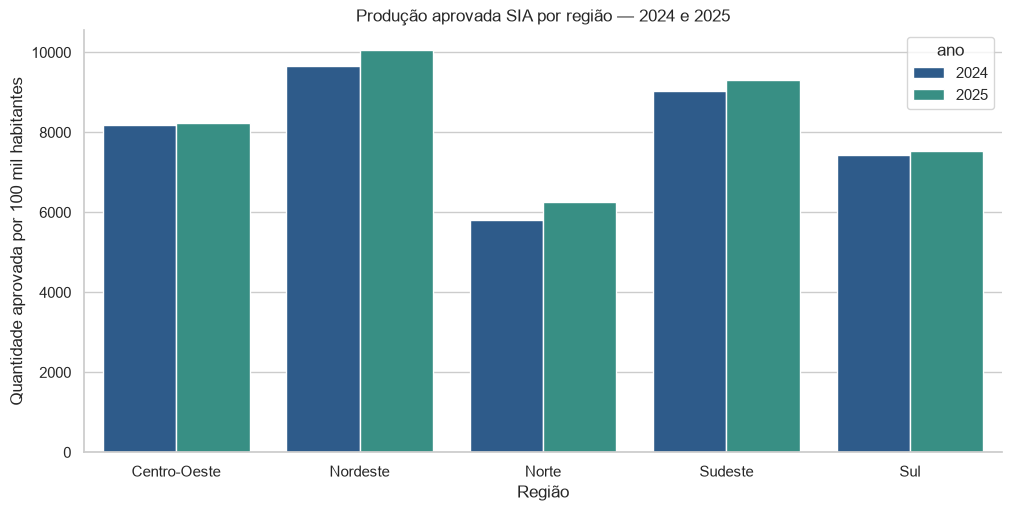

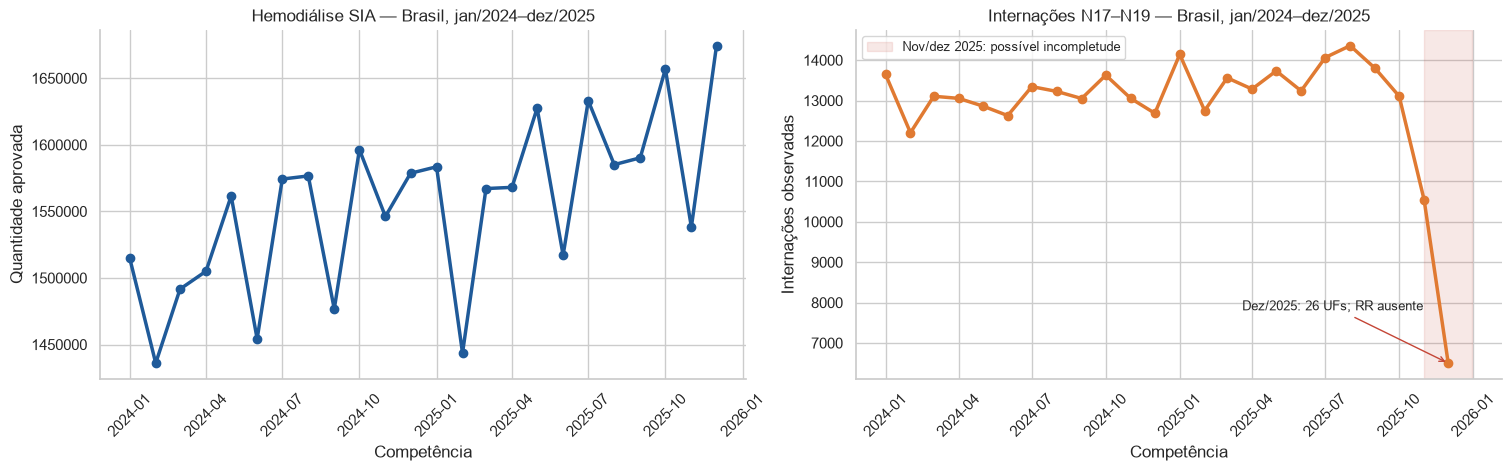

In [4]:
variaveis = ['sia_hemodialise_quantidade_aprovada', 'sih_n17_n19_internacoes_tabnet']
nomes = {'sia_hemodialise_quantidade_aprovada': 'SIA: quantidade aprovada', 'sih_n17_n19_internacoes_tabnet': 'SIH: internações N17–N19'}

resumo = (painel[variaveis].describe(percentiles=[.25, .5, .75]).T
          .rename(index=nomes, columns={'50%': 'mediana', '25%': 'q1', '75%': 'q3', 'count': 'n'})
          [['n', 'mean', 'std', 'min', 'q1', 'mediana', 'q3', 'max']].round(1))
display(resumo)

assert (painel.groupby(['sigla_uf', 'ano'])['populacao_ibge_referencia_anual'].nunique() == 1).all()
sia_anual_uf = (painel.groupby(['sigla_uf', 'uf', 'regiao', 'ano'], as_index=False)
                .agg(sia_quantidade_aprovada=('sia_hemodialise_quantidade_aprovada', 'sum'),
                     populacao_ibge_referencia_anual=('populacao_ibge_referencia_anual', 'first')))
sia_anual_uf['taxa_sia_por_100_mil'] = (
    100_000 * sia_anual_uf['sia_quantidade_aprovada'] / sia_anual_uf['populacao_ibge_referencia_anual']
)
display(sia_anual_uf.sort_values(['ano', 'taxa_sia_por_100_mil'], ascending=[True, False])
        .style.format({'sia_quantidade_aprovada': '{:,.0f}', 'populacao_ibge_referencia_anual': '{:,.0f}',
                       'taxa_sia_por_100_mil': '{:,.1f}'}))

taxa_sia_regional = (sia_anual_uf.groupby(['regiao', 'ano'], as_index=False)
                    .agg(sia_quantidade_aprovada=('sia_quantidade_aprovada', 'sum'),
                         populacao_ibge_referencia_anual=('populacao_ibge_referencia_anual', 'sum')))
taxa_sia_regional['taxa_sia_por_100_mil'] = (
    100_000 * taxa_sia_regional['sia_quantidade_aprovada'] / taxa_sia_regional['populacao_ibge_referencia_anual']
)
display(taxa_sia_regional.sort_values(['ano', 'regiao'])
        .style.format({'sia_quantidade_aprovada': '{:,.0f}', 'populacao_ibge_referencia_anual': '{:,.0f}',
                       'taxa_sia_por_100_mil': '{:,.1f}'}))

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
sns.barplot(data=taxa_sia_regional, x='regiao', y='taxa_sia_por_100_mil', hue='ano', palette=[CORES['sia'], CORES['destaque']], ax=ax)
ax.set(title='Produção aprovada SIA por região — 2024 e 2025', xlabel='Região', ylabel='Quantidade aprovada por 100 mil habitantes')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

serie_brasil = (painel.groupby('data', as_index=False)
                .agg(sia=('sia_hemodialise_quantidade_aprovada', 'sum'),
                     sih=('sih_n17_n19_internacoes_tabnet', 'sum'),
                     ufs_sih=('sih_n17_n19_internacoes_tabnet', 'count')))
serie_brasil['rotulo'] = serie_brasil['data'].dt.strftime('%m/%Y')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), layout='constrained')
axes[0].plot(serie_brasil['data'], serie_brasil['sia'], marker='o', color=CORES['sia'], linewidth=2.5)
axes[0].set(title='Hemodiálise SIA — Brasil, jan/2024–dez/2025', ylabel='Quantidade aprovada', xlabel='Competência')
axes[1].plot(serie_brasil['data'], serie_brasil['sih'], marker='o', color=CORES['sih'], linewidth=2.5)
axes[1].axvspan(pd.Timestamp('2025-11-01'), pd.Timestamp('2025-12-31'), color=CORES['alerta'], alpha=.12, label='Nov/dez 2025: possível incompletude')
axes[1].set(title='Internações N17–N19 — Brasil, jan/2024–dez/2025', ylabel='Internações observadas', xlabel='Competência')
axes[1].legend(frameon=True, fontsize=9)
axes[1].annotate('Dez/2025: 26 UFs; RR ausente',
                 xy=(serie_brasil.iloc[-1]['data'], serie_brasil.iloc[-1]['sih']),
                 xytext=(-18, 38), textcoords='offset points', ha='right', fontsize=9,
                 arrowprops={'arrowstyle': '->', 'color': CORES['alerta']})
for ax in axes:
    ax.ticklabel_format(axis='y', style='plain')
    ax.tick_params(axis='x', rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

### 6.3 Comparação pareada entre períodos — variações absoluta e percentual

**Procedimento:** somar janeiro–outubro por UF em cada ano, parear a mesma UF e calcular:

$$\Delta = x_{2025}-x_{2024}, \qquad \Delta\% = 100\left(\frac{x_{2025}}{x_{2024}}-1\right).$$

**Leitura:** a diferença absoluta dimensiona volume; a percentual dimensiona mudança relativa. O ranking não mede qualidade assistencial. A tabela `comparacao` gerada abaixo será usada no estudo de probabilidades e nos testes.

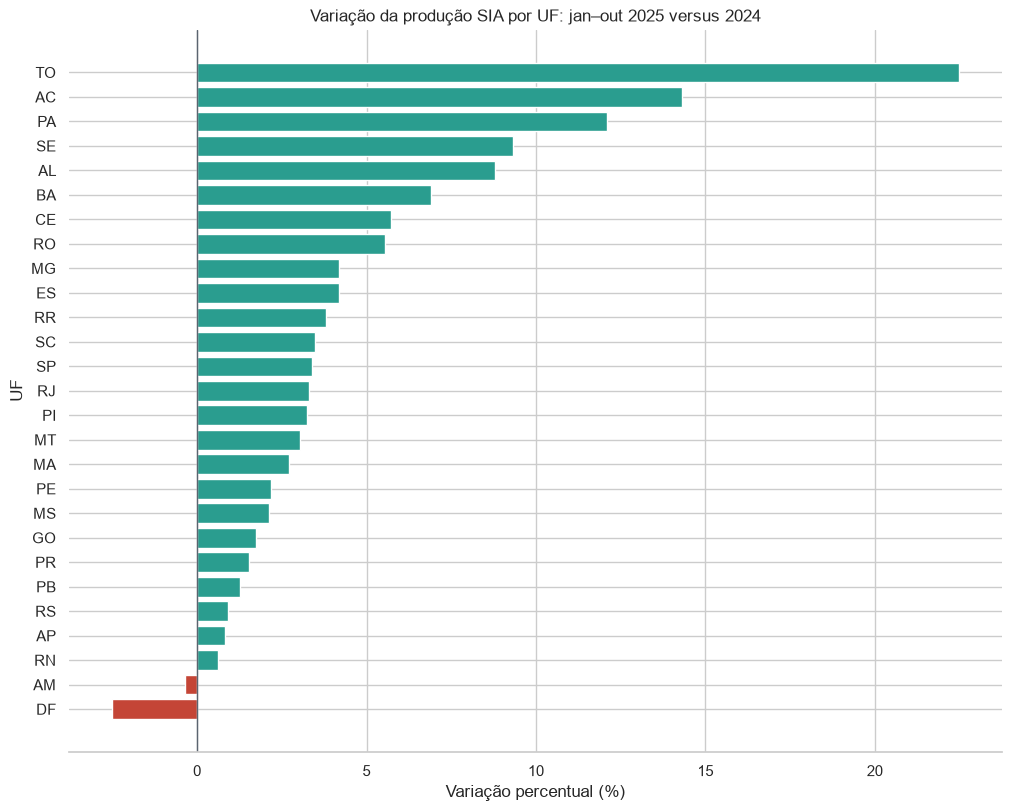

,sigla_uf,regiao,sia_variacao_absoluta,sia_variacao_pct,sih_variacao_absoluta,sih_variacao_pct
26,TO,Norte,15700.0,22.49,104.0,12.41
0,AC,Norte,8798.0,14.30,-18.0,-5.16
13,PA,Norte,51707.0,12.09,74.0,1.33
24,SE,Nordeste,13694.0,9.33,-67.0,-8.45
1,AL,Nordeste,22921.0,8.79,117.0,6.22
4,BA,Nordeste,79105.0,6.89,98.0,1.07
5,CE,Nordeste,45434.0,5.71,228.0,5.43
20,RO,Norte,6210.0,5.55,-53.0,-5.17
10,MG,Sudeste,79272.0,4.20,407.0,2.38
7,ES,Sudeste,12037.0,4.18,359.0,12.65


In [5]:
jan_out = painel.loc[painel['mes'].between(1, 10)].copy()
por_uf = (jan_out.groupby(['sigla_uf', 'uf', 'regiao', 'ano'], as_index=False)
          .agg(sia=('sia_hemodialise_quantidade_aprovada', 'sum'), sih=('sih_n17_n19_internacoes_tabnet', 'sum')))
comparacao = (por_uf.pivot(index=['sigla_uf', 'uf', 'regiao'], columns='ano', values=['sia', 'sih'])
              .reset_index())
comparacao.columns = ['sigla_uf', 'uf', 'regiao', 'sia_2024', 'sia_2025', 'sih_2024', 'sih_2025']
for medida in ['sia', 'sih']:
    comparacao[f'{medida}_variacao_absoluta'] = comparacao[f'{medida}_2025'] - comparacao[f'{medida}_2024']
    comparacao[f'{medida}_variacao_pct'] = 100 * (comparacao[f'{medida}_2025'] / comparacao[f'{medida}_2024'] - 1)

ordenado = comparacao.sort_values('sia_variacao_pct')
fig, ax = plt.subplots(figsize=(10, 8), layout='constrained')
cores_barras = np.where(ordenado['sia_variacao_pct'] >= 0, CORES['destaque'], CORES['alerta'])
ax.barh(ordenado['sigla_uf'], ordenado['sia_variacao_pct'], color=cores_barras)
ax.axvline(0, color=CORES['cinza'], linewidth=1)
ax.set(title='Variação da produção SIA por UF: jan–out 2025 versus 2024', xlabel='Variação percentual (%)', ylabel='UF')
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

colunas_comparacao = ['sigla_uf', 'regiao', 'sia_variacao_absoluta', 'sia_variacao_pct', 'sih_variacao_absoluta', 'sih_variacao_pct']
display(comparacao[colunas_comparacao].sort_values('sia_variacao_pct', ascending=False).round(2))

### 6.4 Plano da exploração adicional: perguntas, unidades e métodos

Os cálculos abaixo aprofundam a seção 12.3 do plano. São descrições adicionais justificadas por perguntas ainda não sistematizadas; não acrescentam testes à família inferencial.

| Pergunta | Dados e unidade | Método e justificativa | Limitação |
|---|---|---|---|
| O crescimento aparece em quais meses? | Total Brasil-mês; 24 meses SIA e jan–out de ambos os anos SIH | Variação homóloga 2025/2024, extremos, CV e variação mês a mês dentro de cada ano; separar nível e oscilação | Contagens mensais não ajustadas por dias; não demonstram sazonalidade estável ou tendência persistente |
| Onde o volume e a mudança se concentram? | 27 UFs e cinco regiões; jan–out | Participação nacional e contribuição em pontos percentuais à mudança, somando volumes antes de calcular razões | UF de atendimento não indica residência; contribuição negativa é preservada |
| Percentual extremo também é grande em volume ou por população? | UF; mudança jan–out e taxa anual SIA | Cercas Q1 − 1,5 IQR e Q3 + 1,5 IQR, diferenças absolutas e taxa anual lado a lado | Sinalizador descritivo, não erro nem exclusão; períodos das medidas diferem |
| As direções SIA/SIH coincidem? | 27 pares de mudanças jan–out | Tabela de nove combinações aumento/empate/redução e conexão com probabilidades e Spearman | Direção conjunta não equivale a associação causal nem independência |

As figuras das seções 6 e 8 apoiam a leitura; as tabelas completas serão exportadas. A janela SIH utilizável é uma decisão analítica, sem confirmação externa de maturidade.


In [6]:
# Comparação homóloga e oscilações: SIH nunca usa nov/dez nesta exploração.
mensal_exploratorio = []
resumo_temporal = []
for indicador, coluna in [('SIA', variaveis[0]), ('SIH', variaveis[1])]:
    dados = painel if indicador == 'SIA' else painel.loc[painel['mes'] <= 10]
    assert dados[coluna].notna().all()
    totais = dados.groupby(['ano', 'mes'])[coluna].sum().unstack('ano')
    tabela = totais.rename(columns={2024: 'valor_2024', 2025: 'valor_2025'}).reset_index()
    tabela['indicador'] = indicador
    tabela['variacao_absoluta'] = tabela.valor_2025 - tabela.valor_2024
    tabela['variacao_pct'] = 100 * tabela.variacao_absoluta / tabela.valor_2024
    mensal_exploratorio.append(tabela)
    for ano in [2024, 2025]:
        serie = totais[ano]
        resumo_temporal.append(dict(indicador=indicador, ano=ano, meses=len(serie),
            total=serie.sum(), media_mensal=serie.mean(), cv_pct=100 * serie.std(ddof=1) / serie.mean(),
            mes_min=int(serie.idxmin()), minimo=serie.min(), mes_max=int(serie.idxmax()), maximo=serie.max(),
            amplitude=serie.max()-serie.min(),
            maior_alta_mensal_pct=100 * serie.pct_change().max(),
            maior_queda_mensal_pct=100 * serie.pct_change().min()))
mensal_exploratorio = pd.concat(mensal_exploratorio, ignore_index=True)
resumo_temporal = pd.DataFrame(resumo_temporal)
display(mensal_exploratorio.round(2))
display(resumo_temporal.round(2))

# Concentração e contribuição: denominador é o total nacional de 2024.
territorios = []
concentracao = []
for indicador in ['sia', 'sih']:
    tabela = comparacao[['sigla_uf', 'regiao', f'{indicador}_2024', f'{indicador}_2025',
                         f'{indicador}_variacao_absoluta', f'{indicador}_variacao_pct']].copy()
    tabela.columns = ['sigla_uf', 'regiao', 'valor_2024', 'valor_2025', 'variacao_absoluta', 'variacao_pct']
    tabela['indicador'] = indicador.upper()
    for ano in [2024, 2025]:
        tabela[f'participacao_{ano}_pct'] = 100 * tabela[f'valor_{ano}'] / tabela[f'valor_{ano}'].sum()
        lideres = tabela.nlargest(5, f'valor_{ano}')
        concentracao.append(dict(indicador=indicador.upper(), ano=ano,
            cinco_maiores_ufs=', '.join(lideres.sigla_uf),
            participacao_cinco_maiores_pct=lideres[f'participacao_{ano}_pct'].sum()))
    tabela['contribuicao_crescimento_pp'] = 100 * tabela.variacao_absoluta / tabela.valor_2024.sum()
    q1, q3 = tabela.variacao_pct.quantile([.25, .75])
    tabela['limite_inferior_iqr'] = q1 - 1.5 * (q3-q1)
    tabela['limite_superior_iqr'] = q3 + 1.5 * (q3-q1)
    tabela['extremo_iqr'] = ((tabela.variacao_pct < tabela.limite_inferior_iqr) |
                             (tabela.variacao_pct > tabela.limite_superior_iqr))
    territorios.append(tabela)
territorios_exploratorios = pd.concat(territorios, ignore_index=True)
# Taxa anual explicitamente separada da comparação jan–out.
taxas = sia_anual_uf.pivot(index='sigla_uf', columns='ano', values='taxa_sia_por_100_mil')
taxas.columns = ['taxa_sia_anual_2024_por_100_mil', 'taxa_sia_anual_2025_por_100_mil']
territorios_exploratorios = territorios_exploratorios.merge(taxas, on='sigla_uf', validate='many_to_one')
concentracao = pd.DataFrame(concentracao)
regional_exploratorio = (territorios_exploratorios.groupby(['indicador', 'regiao'], as_index=False)
    [['valor_2024', 'valor_2025', 'variacao_absoluta', 'contribuicao_crescimento_pp']].sum())
regional_exploratorio['variacao_pct'] = 100 * regional_exploratorio.variacao_absoluta / regional_exploratorio.valor_2024

display(concentracao.round(2))
display(regional_exploratorio.round(2))
display(territorios_exploratorios.loc[territorios_exploratorios.extremo_iqr].round(2))

# Empate não é redução. Reindexar preserva categorias com frequência zero.
def direcao_exploratoria(valores):
    return np.select([valores > 0, valores < 0], ['aumento', 'reducao'], default='empate')
conjunta_ufs = comparacao[['sigla_uf', 'sia_variacao_pct', 'sih_variacao_pct']].copy()
conjunta_ufs['direcao_sia'] = direcao_exploratoria(conjunta_ufs.sia_variacao_pct)
conjunta_ufs['direcao_sih'] = direcao_exploratoria(conjunta_ufs.sih_variacao_pct)
categorias = ['aumento', 'empate', 'reducao']
indice = pd.MultiIndex.from_product([categorias, categorias], names=['direcao_sia', 'direcao_sih'])
mudancas_conjuntas = (conjunta_ufs.groupby(['direcao_sia', 'direcao_sih']).size()
    .reindex(indice, fill_value=0).rename('n_ufs').reset_index())
mudancas_conjuntas['proporcao_pct'] = 100 * mudancas_conjuntas.n_ufs / len(comparacao)
display(mudancas_conjuntas.round(2))
display(conjunta_ufs.sort_values(['direcao_sia', 'direcao_sih', 'sigla_uf']))

assert len(mensal_exploratorio) == 22
assert resumo_temporal.meses.tolist() == [12, 12, 10, 10]
assert mudancas_conjuntas.n_ufs.sum() == 27
for indicador, grupo in territorios_exploratorios.groupby('indicador'):
    for ano in [2024, 2025]:
        assert np.isclose(grupo[f'participacao_{ano}_pct'].sum(), 100)
    assert np.isclose(grupo.contribuicao_crescimento_pp.sum(),
                      100 * grupo.variacao_absoluta.sum() / grupo.valor_2024.sum())


ano,mes,valor_2024,valor_2025,indicador,variacao_absoluta,variacao_pct
0,1,1514799.0,1583484.0,SIA,68685.0,4.53
1,2,1436017.0,1443598.0,SIA,7581.0,0.53
2,3,1491604.0,1567136.0,SIA,75532.0,5.06
3,4,1505045.0,1568041.0,SIA,62996.0,4.19
4,5,1561557.0,1627526.0,SIA,65969.0,4.22
5,6,1454230.0,1517095.0,SIA,62865.0,4.32
6,7,1574273.0,1633118.0,SIA,58845.0,3.74
7,8,1576610.0,1585108.0,SIA,8498.0,0.54
8,9,1476696.0,1590230.0,SIA,113534.0,7.69
9,10,1596370.0,1656879.0,SIA,60509.0,3.79


,indicador,ano,meses,total,media_mensal,cv_pct,mes_min,minimo,mes_max,maximo,amplitude,maior_alta_mensal_pct,maior_queda_mensal_pct
0,SIA,2024,12,18311982.0,1525998.5,3.52,2,1436017.0,10,1596370.0,160353.0,8.25,-6.87
1,SIA,2025,12,18984870.0,1582072.5,4.03,2,1443598.0,12,1674455.0,230857.0,8.86,-8.83
2,SIH,2024,10,130752.0,13075.2,3.36,2,12204.0,1,13647.0,1443.0,7.39,-10.57
3,SIH,2025,10,136036.0,13603.6,3.75,2,12750.0,8,14358.0,1608.0,6.37,-9.84


,indicador,ano,cinco_maiores_ufs,participacao_cinco_maiores_pct
0,SIA,2024,"SP, MG, BA, RJ, PE",54.97
1,SIA,2025,"SP, MG, BA, RJ, PE",55.00
2,SIH,2024,"SP, MG, RJ, BA, RS",57.12
3,SIH,2025,"SP, MG, RJ, BA, PR",56.62


,indicador,regiao,valor_2024,valor_2025,variacao_absoluta,contribuicao_crescimento_pp,variacao_pct
0,SIA,Centro-Oeste,1162159.0,1180420.0,18261.0,0.12,1.57
1,SIA,Nordeste,4575532.0,4783582.0,208050.0,1.37,4.55
2,SIA,Norte,894120.0,977807.0,83687.0,0.55,9.36
3,SIA,Sudeste,6631769.0,6873133.0,241364.0,1.59,3.64
4,SIA,Sul,1923621.0,1957273.0,33652.0,0.22,1.75
5,SIH,Centro-Oeste,8936.0,9426.0,490.0,0.37,5.48
6,SIH,Nordeste,29559.0,30213.0,654.0,0.50,2.21
7,SIH,Norte,10993.0,11686.0,693.0,0.53,6.30
8,SIH,Sudeste,59436.0,61857.0,2421.0,1.85,4.07
9,SIH,Sul,21828.0,22854.0,1026.0,0.78,4.70


,sigla_uf,regiao,valor_2024,valor_2025,variacao_absoluta,variacao_pct,indicador,participacao_2024_pct,participacao_2025_pct,contribuicao_crescimento_pp,limite_inferior_iqr,limite_superior_iqr,extremo_iqr,taxa_sia_anual_2024_por_100_mil,taxa_sia_anual_2025_por_100_mil
0,AC,Norte,61514.0,70312.0,8798.0,14.30,SIA,0.41,0.45,0.06,-4.34,11.61,True,8504.24,9636.89
13,PA,Norte,427643.0,479350.0,51707.0,12.09,SIA,2.82,3.04,0.34,-4.34,11.61,True,5976.38,6647.00
26,TO,Norte,69798.0,85498.0,15700.0,22.49,SIA,0.46,0.54,0.10,-4.34,11.61,True,5447.07,6441.59
30,AP,Norte,305.0,416.0,111.0,36.39,SIH,0.23,0.31,0.08,-22.15,27.65,True,6980.74,6781.88
48,RR,Norte,500.0,352.0,-148.0,-29.60,SIH,0.38,0.26,-0.11,-22.15,27.65,True,6183.10,6195.69


,direcao_sia,direcao_sih,n_ufs,proporcao_pct
0,aumento,aumento,15,55.56
1,aumento,empate,0,0.00
2,aumento,reducao,10,37.04
3,empate,aumento,0,0.00
4,empate,empate,0,0.00
5,empate,reducao,0,0.00
6,reducao,aumento,2,7.41
7,reducao,empate,0,0.00
8,reducao,reducao,0,0.00


,sigla_uf,sia_variacao_pct,sih_variacao_pct,direcao_sia,direcao_sih
1,AL,8.792368,6.220096,aumento,aumento
3,AP,0.818190,36.393443,aumento,aumento
4,BA,6.888555,1.070570,aumento,aumento
5,CE,5.712655,5.429864,aumento,aumento
7,ES,4.179369,12.649753,aumento,aumento
8,GO,1.742085,15.820584,aumento,aumento
9,MA,2.703901,10.103368,aumento,aumento
10,MG,4.199443,2.375671,aumento,aumento
13,PA,12.091160,1.331893,aumento,aumento
15,PE,2.189457,4.721418,aumento,aumento


<a id="secao-7"></a>

## 7. Estudo de probabilidades

**Objetivo de aprendizagem:** aplicar probabilidade simples, interseção e união de eventos aos dados reais do estudo, relacionando fórmula, contagem e interpretação.

### 7.1 Experimento, espaço amostral e eventos

**Experimento:** escolher ao acaso uma UF entre as 27 UFs do Brasil, com a mesma chance para cada uma. A observação desta seção é uma **UF**, não uma linha mensal e nem uma pessoa.

**Período:** comparar o total de janeiro–outubro de 2025 com o total de janeiro–outubro de 2024. A tabela `comparacao`, construída na seção 6, contém uma linha por UF e as variações dos dois indicadores.

- Espaço amostral: $\Omega =$ conjunto das 27 UFs; $|\Omega| = 27$.
- Evento $A$: a quantidade aprovada de hemodiálise SIA aumentou na UF.
- Evento $B$: as internações N17–N19 SIH aumentaram na UF.
- Aumento: variação **maior que zero**; redução: variação **menor que zero**. Variação igual a zero é empate, não redução.

Como todas as UFs têm o mesmo peso neste experimento, para um evento $E$:

$$P(E)=\frac{n(E)}{n(\Omega)}=\frac{\text{UFs favoráveis ao evento}}{\text{UFs observadas}}.$$

As probabilidades são empíricas e conhecidas neste conjunto territorial. A escolha aleatória da UF define o experimento didático; ela não transforma os dados administrativos em amostra aleatória de pacientes.

In [7]:
colunas_variacao = ['sia_variacao_pct', 'sih_variacao_pct']
assert comparacao[colunas_variacao].notna().all().all(), 'As duas variações devem estar observadas para todas as UFs.'
n_ufs = comparacao['sigla_uf'].nunique()
assert n_ufs == len(comparacao), 'Cada UF deve aparecer uma única vez.'
assert n_ufs > 0

# Vetores lógicos: True identifica uma UF pertencente ao evento.
evento_a = comparacao['sia_variacao_pct'] > 0
evento_b = comparacao['sih_variacao_pct'] > 0
reducao_sia = comparacao['sia_variacao_pct'] < 0
reducao_sih = comparacao['sih_variacao_pct'] < 0

print(f'Espaço amostral: {n_ufs} UFs, com pesos iguais.')
print('Período: janeiro–outubro de 2025 versus janeiro–outubro de 2024.')
print(f'Empates: SIA = {(comparacao.sia_variacao_pct == 0).sum()}; SIH = {(comparacao.sih_variacao_pct == 0).sum()}.')

Espaço amostral: 27 UFs, com pesos iguais.
Período: janeiro–outubro de 2025 versus janeiro–outubro de 2024.
Empates: SIA = 0; SIH = 0.


### 7.2 Probabilidade 1 — aumento da produção SIA

**Pergunta:** Qual a probabilidade de a UF escolhida ter apresentado aumento da quantidade aprovada de hemodiálise?

**Fórmula:**

$$P(A)=\frac{n(A)}{n(\Omega)}$$

In [8]:
n_a = int(evento_a.sum())
p_a = n_a / n_ufs

print(f'P(A) = {n_a}/{n_ufs} = {p_a:.4f} = {100 * p_a:.2f}%'.replace('.', ','))

P(A) = 25/27 = 0,9259 = 92,59%


**Interpretação:** 25 das 27 UFs apresentaram aumento SIA. Portanto, ao escolher uma UF com chances iguais, a probabilidade de selecionar uma que apresentou esse aumento é **92,59%**. Trata-se da frequência de UFs com aumento, não da participação dessas UFs na produção nacional.

### 7.3 Probabilidade 2 — aumento das internações SIH

**Pergunta:** Qual a probabilidade de a UF escolhida ter apresentado aumento das internações N17–N19?

**Fórmula:**

$$P(B)=\frac{n(B)}{n(\Omega)}$$

In [9]:
n_b = int(evento_b.sum())
p_b = n_b / n_ufs

print(f'P(B) = {n_b}/{n_ufs} = {p_b:.4f} = {100 * p_b:.2f}%'.replace('.', ','))

P(B) = 17/27 = 0,6296 = 62,96%


**Interpretação:** 17 das 27 UFs apresentaram aumento SIH, correspondendo a **62,96%**. Esse resultado descreve a direção das internações registradas por território; não representa a probabilidade de uma pessoa ser internada.

### 7.4 Probabilidade 3 — aumento simultâneo dos dois indicadores

**Pergunta:** Qual a probabilidade de a UF escolhida ter apresentado aumento tanto no SIA quanto no SIH?

**Fórmula:**

$$P(A\cap B)=\frac{n(A\cap B)}{n(\Omega)}$$

In [10]:
# Interseção: a UF precisa satisfazer as duas condições (&).
n_ambos_aumentam = int((evento_a & evento_b).sum())
p_ambos_aumentam = n_ambos_aumentam / n_ufs

print(f'P(A ∩ B) = {n_ambos_aumentam}/{n_ufs} = {p_ambos_aumentam:.4f} = {100 * p_ambos_aumentam:.2f}%'.replace('.', ','))

P(A ∩ B) = 15/27 = 0,5556 = 55,56%


**Interpretação:** 15 das 27 UFs apresentaram aumento dos dois indicadores, logo a probabilidade empírica é **55,56%**. A contagem usa os eventos observados conjuntamente; não se pressupõe independência e não se calcula a interseção multiplicando as probabilidades marginais. Crescimento simultâneo não demonstra relação causal.

### 7.5 Probabilidade 4 — aumento de pelo menos um indicador

**Pergunta:** Qual a probabilidade de a UF escolhida ter apresentado aumento no SIA, no SIH ou em ambos?

**Fórmula:**

$$P(A\cup B)=\frac{n(A\cup B)}{n(\Omega)}=P(A)+P(B)-P(A\cap B)$$

In [11]:
# União inclusiva: basta satisfazer uma condição, incluindo ambas (|).
n_ao_menos_um = int((evento_a | evento_b).sum())
p_ao_menos_um = n_ao_menos_um / n_ufs

# A subtração da interseção evita contar a mesma UF duas vezes.
assert abs(p_ao_menos_um - (p_a + p_b - p_ambos_aumentam)) < 1e-12

print(f'P(A ∪ B) = {n_ao_menos_um}/{n_ufs} = {p_ao_menos_um:.4f} = {100 * p_ao_menos_um:.2f}%'.replace('.', ','))

P(A ∪ B) = 27/27 = 1,0000 = 100,00%


**Interpretação:** todas as 27 UFs apresentaram aumento em pelo menos um dos indicadores, resultando em **100%** neste conjunto. Isso não significa que ambos aumentaram em todas as UFs: a interseção contém apenas 15. O valor de 100% também não garante o mesmo comportamento em períodos futuros.

### 7.6 Probabilidade 5 — redução simultânea dos dois indicadores

**Pergunta:** Qual a probabilidade de a UF escolhida ter apresentado redução tanto no SIA quanto no SIH?

**Fórmula:**

$$P(\text{redução SIA}\cap\text{redução SIH})=\frac{n(\text{UFs com duas reduções})}{n(\Omega)}$$

In [12]:
# Redução exige variação estritamente negativa nos dois indicadores.
# Não usar simplesmente o complemento do aumento: pode haver empates.
n_ambos_diminuem = int((reducao_sia & reducao_sih).sum())
p_ambos_diminuem = n_ambos_diminuem / n_ufs

print(f'P(redução SIA ∩ redução SIH) = {n_ambos_diminuem}/{n_ufs} = {p_ambos_diminuem:.4f} = {100 * p_ambos_diminuem:.2f}%'.replace('.', ','))

P(redução SIA ∩ redução SIH) = 0/27 = 0,0000 = 0,00%


**Interpretação:** nenhuma UF apresentou redução simultânea dos dois indicadores; a probabilidade empírica é **0%**. Isso significa que o evento não ocorreu nesta comparação, sem indicar impossibilidade em outro período ou contexto. Neste conjunto não houve empates; somente nessa situação a dupla redução coincide com o complemento da união dos aumentos.

### 7.7 Quadro-resumo das cinco probabilidades

A tabela reúne as contagens e probabilidades calculadas acima. Os numeradores representam eventos diferentes e sobrepostos; portanto, **as cinco probabilidades não devem ser somadas como se fossem categorias mutuamente exclusivas**.

In [13]:
estudo_probabilidades = pd.DataFrame({
    'evento': ['Aumento SIA', 'Aumento SIH', 'Ambos aumentam',
               'Ao menos um aumenta', 'Ambos diminuem'],
    'ufs_favoraveis': [n_a, n_b, n_ambos_aumentam, n_ao_menos_um, n_ambos_diminuem],
    'ufs_total': [n_ufs] * 5,
    'probabilidade': [p_a, p_b, p_ambos_aumentam, p_ao_menos_um, p_ambos_diminuem],
})
display(estudo_probabilidades.style.format({
    'probabilidade': lambda valor: f'{valor:.2%}'.replace('.', ',')
}).hide(axis='index'))

evento,ufs_favoraveis,ufs_total,probabilidade
Aumento SIA,25,27,"92,59%"
Aumento SIH,17,27,"62,96%"
Ambos aumentam,15,27,"55,56%"
Ao menos um aumenta,27,27,"100,00%"
Ambos diminuem,0,27,"0,00%"


**Síntese da seção:** o aumento SIA foi mais disseminado territorialmente do que o aumento SIH. Houve aumento conjunto em 15 UFs, aumento em pelo menos um indicador em todas as UFs e nenhuma dupla redução. Esses resultados respondem sobre frequência territorial de mudanças observadas, sem estimar pacientes, acesso, efetividade ou crescimento futuro.

### 7.8 Complemento — intervalos binomiais de referência

A seguir, preserva-se o cálculo dos intervalos exatos de 95% para as probabilidades marginais de aumento SIA e SIH. Como as 27 UFs constituem o conjunto territorial observado, as proporções anteriores são conhecidas nesse conjunto; os intervalos são condicionados ao modelo binomial de referência e não representam erro amostral de um censo. A dependência espacial entre UFs limita esse modelo.

In [14]:
def proporcao_com_ic(valores):
    sucessos = int((valores > 0).sum())
    total = valores.notna().sum()
    ic = stats.binomtest(sucessos, total).proportion_ci(confidence_level=.95, method='exact')
    return pd.Series({'ufs_com_aumento': sucessos, 'ufs_validas': total, 'probabilidade_empirica': sucessos / total, 'ic95_inferior': ic.low, 'ic95_superior': ic.high})

probabilidades = pd.DataFrame({
    'SIA': proporcao_com_ic(comparacao['sia_variacao_pct']),
    'SIH': proporcao_com_ic(comparacao['sih_variacao_pct'])
}).T
display(probabilidades.style.format({'probabilidade_empirica': '{:.1%}', 'ic95_inferior': '{:.1%}', 'ic95_superior': '{:.1%}'}))

,ufs_com_aumento,ufs_validas,probabilidade_empirica,ic95_inferior,ic95_superior
SIA,25.000000,27.000000,92.6%,75.7%,99.1%
SIH,17.000000,27.000000,63.0%,42.4%,80.6%


<a id="secao-8"></a>

## 8. Inferência exploratória — testes de hipóteses e associação

O teste binomial de sinais verifica se aumentos e reduções entre UFs são igualmente frequentes. A correlação de Spearman avalia associação monotônica entre variações percentuais. Os testes são bilaterais, com nível de 5%, e têm interpretação exploratória.

A família de Holm neste caderno contém exatamente três testes: sinais SIA, sinais SIH e Spearman entre variações. P-valores ajustados em outras famílias do notebook 04 não são diretamente intercambiáveis.

### 8.1 Teste binomial exato de sinais — direção das mudanças

**Pergunta:** entre as UFs com mudança, aumentos e reduções são igualmente frequentes?

**Hipóteses:** H₀: proporção de aumentos = 0,5; H₁: proporção diferente de 0,5. O teste é bilateral e aplicado separadamente a SIA e SIH. Empates não entram no denominador do teste de sinais; nesta comparação não há empates.

### 8.2 Correlação de Spearman — associação entre variações

**Pergunta:** UFs com maiores variações SIA também tendem a apresentar maiores variações SIH?

**Método:** correlação por postos entre as duas variações percentuais, com uma observação pareada por UF. O p-valor bilateral usa a referência de correlação nula; ele não testa causalidade nem comprova independência.

### 8.3 Ajuste de Holm — multiplicidade

**Método:** ajustar os três p-valores da família (dois testes de sinais e uma correlação). A tabela mostra p bruto e ajustado; a leitura exploratória de 5% usa o ajustado.

### 8.4 Execução e resultados dos três testes

A célula seguinte executa os métodos acima e mostra a tabela conjunta e a dispersão. **Interpretação:** há predomínio direcional de aumento SIA; os resultados SIH e Spearman não fornecem evidência suficiente após Holm. Ausência de significância não demonstra estabilidade ou ausência de associação.

,análise,estatistica_ou_positivos,negativos,p_valor,p_valor_holm,conclusao_exploratoria_5pct
0,Mudança direcional SIA,25.000,2.000000,5.648e-06,1.694e-05,Evidência contra H0
1,Mudança direcional SIH,17.000,10.000000,0.2478,0.4275,Sem evidência contra H0
2,Correlação Spearman: variação SIA × SIH,-0.247,nan,0.2137,0.4275,Sem evidência contra H0


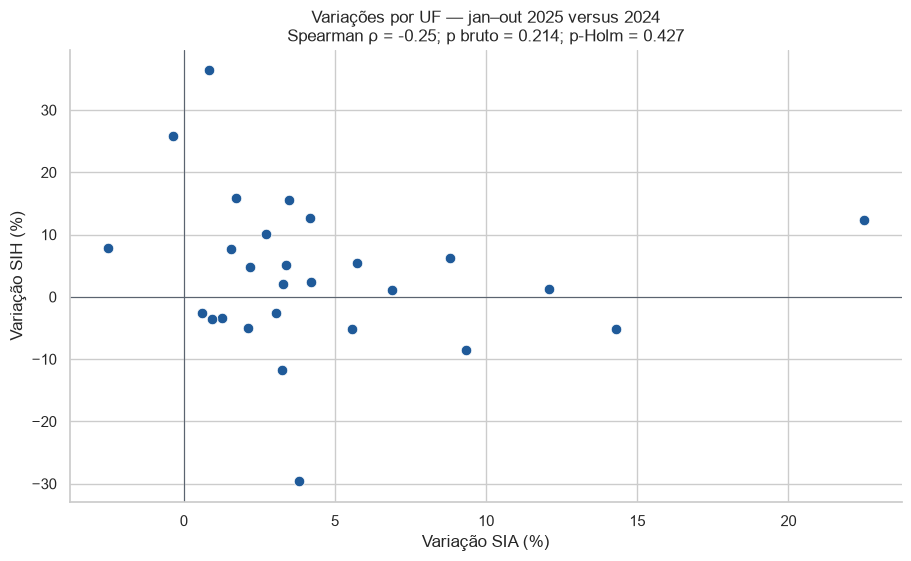

In [15]:
def teste_sinais(variacao):
    positivos = int((variacao > 0).sum())
    negativos = int((variacao < 0).sum())
    resultado = stats.binomtest(positivos, positivos + negativos, p=.5, alternative='two-sided')
    return positivos, negativos, resultado.pvalue

sia_pos, sia_neg, p_sia = teste_sinais(comparacao['sia_variacao_pct'])
sih_pos, sih_neg, p_sih = teste_sinais(comparacao['sih_variacao_pct'])
rho, p_rho = stats.spearmanr(comparacao['sia_variacao_pct'], comparacao['sih_variacao_pct'])

inferencias = pd.DataFrame([
    ['Mudança direcional SIA', sia_pos, sia_neg, p_sia],
    ['Mudança direcional SIH', sih_pos, sih_neg, p_sih],
    ['Correlação Spearman: variação SIA × SIH', rho, np.nan, p_rho],
], columns=['análise', 'estatistica_ou_positivos', 'negativos', 'p_valor'])
inferencias['p_valor_holm'] = multipletests(inferencias['p_valor'], method='holm')[1]
inferencias['conclusao_exploratoria_5pct'] = np.where(inferencias['p_valor_holm'] < .05, 'Evidência contra H0', 'Sem evidência contra H0')
display(inferencias.style.format({'estatistica_ou_positivos': '{:.3f}', 'p_valor': '{:.4g}', 'p_valor_holm': '{:.4g}'}))

fig, ax = plt.subplots(figsize=(9, 5.5), layout='constrained')
sns.scatterplot(data=comparacao, x='sia_variacao_pct', y='sih_variacao_pct', s=58, color=CORES['sia'], ax=ax)
ax.axhline(0, color=CORES['cinza'], linewidth=.8); ax.axvline(0, color=CORES['cinza'], linewidth=.8)
ax.set(title=f'Variações por UF — jan–out 2025 versus 2024\nSpearman ρ = {rho:.2f}; p bruto = {p_rho:.3f}; p-Holm = {inferencias.iloc[2]["p_valor_holm"]:.3f}', xlabel='Variação SIA (%)', ylabel='Variação SIH (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

### 8.5 Comparação regional — pressupostos, ANOVA e Kruskal–Wallis

A comparação usa a variação percentual SIA de janeiro–outubro entre 2024 e 2025. Cada UF aparece uma única vez. Primeiro, são verificados normalidade por região (Shapiro–Wilk) e homogeneidade das variâncias (Levene). A ANOVA é exibida como referência; quando os pressupostos falham, a conclusão usa Kruskal–Wallis. Os grupos regionais são pequenos, portanto a leitura é complementar e exploratória.

Kruskal–Wallis compara distribuições por postos; com dispersões diferentes, não isola diferenças de medianas. Não significância não demonstra igualdade. Sul (3 UFs) e Centro-Oeste (4 UFs) têm os menores grupos.

**Roteiro metodológico:**

1. Shapiro–Wilk avalia a compatibilidade com normalidade dentro de cada região; grupos pequenos limitam a avaliação.
2. Levene com centro na mediana avalia homogeneidade das variâncias.
3. A ANOVA clássica é exibida como referência didática; a seleção neste painel leva a Kruskal–Wallis, pois Levene p = 0,037.
4. Kruskal–Wallis p = 0,248 fornece evidência insuficiente de diferença entre distribuições regionais. Não se conclui igualdade entre regiões.

O p-valor regional é complementar, apresentado separadamente da família Holm dos três testes anteriores.

,regiao,p_shapiro
0,Centro-Oeste,0.1525
1,Nordeste,0.3359
2,Norte,0.5147
3,Sudeste,0.0794
4,Sul,0.4504


,p_Levene,p_ANOVA,p_Kruskal_Wallis,método_para_interpretação
0,0.0370,0.1580,0.2484,Kruskal–Wallis


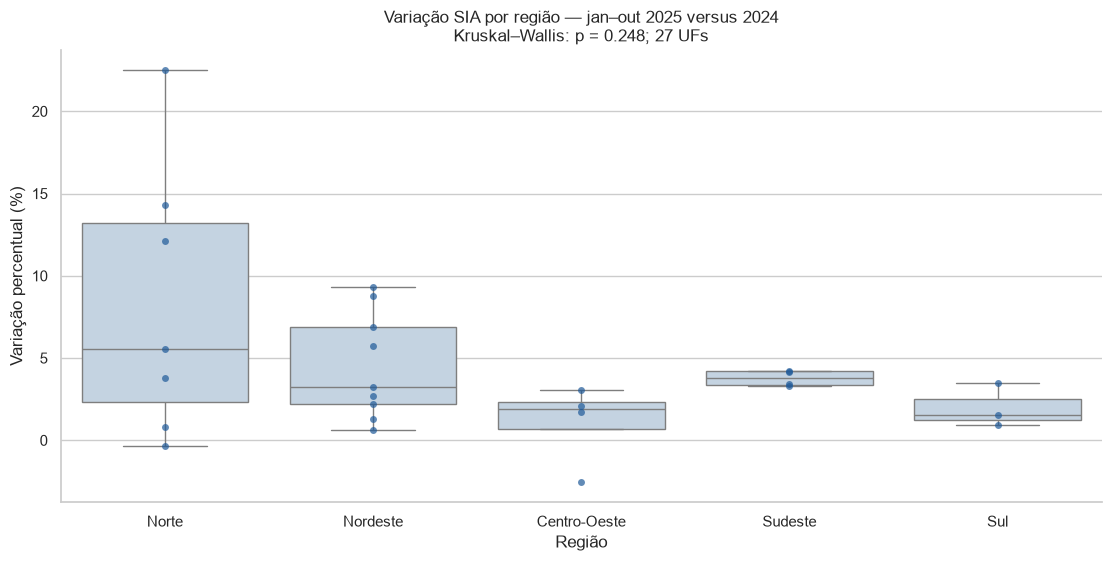

In [16]:
variacao_regional = comparacao[['sigla_uf', 'regiao', 'sia_variacao_pct']].copy()
grupos_regionais = [grupo['sia_variacao_pct'].to_numpy() for _, grupo in variacao_regional.groupby('regiao', sort=False)]
normalidade = (variacao_regional.groupby('regiao')['sia_variacao_pct']
               .apply(lambda valores: stats.shapiro(valores).pvalue)
               .rename('p_shapiro').reset_index())
p_levene = stats.levene(*grupos_regionais, center='median').pvalue
p_anova = stats.f_oneway(*grupos_regionais).pvalue
p_kruskal = stats.kruskal(*grupos_regionais).pvalue
pressupostos_atendidos = bool((normalidade['p_shapiro'] > .05).all() and p_levene > .05)
metodo_recomendado = 'ANOVA clássica' if pressupostos_atendidos else 'Kruskal–Wallis'

display(normalidade.style.format({'p_shapiro': '{:.4f}'}))
display(pd.DataFrame([{
    'p_Levene': p_levene, 'p_ANOVA': p_anova, 'p_Kruskal_Wallis': p_kruskal,
    'método_para_interpretação': metodo_recomendado
}]).style.format({'p_Levene': '{:.4f}', 'p_ANOVA': '{:.4f}', 'p_Kruskal_Wallis': '{:.4f}'}))

fig, ax = plt.subplots(figsize=(11, 5.5), layout='constrained')
sns.boxplot(data=variacao_regional, x='regiao', y='sia_variacao_pct', color='#BFD3E6', showfliers=False, ax=ax)
sns.stripplot(data=variacao_regional, x='regiao', y='sia_variacao_pct', color=CORES['sia'], alpha=.7, jitter=False, ax=ax)
ax.set(title=f'Variação SIA por região — jan–out 2025 versus 2024\n{metodo_recomendado}: p = {p_kruskal:.3f}; 27 UFs', xlabel='Região', ylabel='Variação percentual (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

<a id="secao-9"></a>

## 9. Modelagem preditiva — validação temporal e cenário exploratório

A previsão usa somente SIA, cuja série está completa. SIH não é modelado porque novembro/dezembro de 2025 exigem investigação de maturidade. Há somente 24 competências; portanto, a projeção é didática e exploratória, não operacional.

**Modelos candidatos:** média móvel de três meses, tendência linear e ingênuo sazonal (mesmo mês do ano anterior). A validação é de origem móvel: cada mês de 2025 é previsto apenas com competências anteriores. O melhor modelo é o de menor MAPE; em empate, menor MAE.

São 12 previsões de um mês à frente, com histórico crescente. O MAPE dessa janela não valida os 12 meses projetados a partir de dezembro de 2025. A seleção e a avaliação usam a mesma janela, sem teste final independente. A cobertura das competências SIA não comprova encerramento administrativo ou ausência de revisões.

### 9.1 Métodos candidatos

| Método | Regra de previsão | Papel didático |
|---|---|---|
| Média móvel de três meses | Média dos três valores mais recentes | Referência de nível local. |
| Tendência linear | Regressão do total mensal contra o índice de tempo | Extrapolação de tendência. |
| Ingênuo sazonal | Valor do mesmo mês do ano anterior | Referência sazonal. |

### 9.2 Validação de origem móvel e métricas de erro

**Procedimento:** gerar 12 previsões de um mês à frente para 2025, treinando somente nos meses anteriores. Comparar MAE (erro absoluto médio), RMSE (raiz do erro quadrático médio) e MAPE (erro percentual absoluto médio). Valores menores indicam menores erros nesta janela. A seleção usa MAPE e MAE como desempate; não é um teste de superioridade estatística.

**Leitura da saída:** a tendência linear apresentou o menor MAPE (3,01%) entre os três candidatos na validação realizada, sem garantir precisão de uma projeção anual.

In [17]:
sia_mensal = serie_brasil[['data', 'sia']].sort_values('data').reset_index(drop=True)
serie_completa = sia_mensal['sia'].to_numpy(dtype=float)

def previsao_media_movel(serie, horizonte, janela=3):
    historico = list(serie.astype(float))
    previsoes = []
    for _ in range(horizonte):
        previsao = np.mean(historico[-janela:])
        previsoes.append(previsao)
        historico.append(previsao)
    return np.array(previsoes)

def previsao_tendencia_linear(serie, horizonte):
    x = np.arange(len(serie))
    inclinacao, intercepto = np.polyfit(x, serie, 1)
    return intercepto + inclinacao * np.arange(len(serie), len(serie) + horizonte)

def previsao_sazonal_ingenua(serie, horizonte):
    historico = list(serie.astype(float))
    previsoes = []
    for _ in range(horizonte):
        previsao = historico[-12]
        previsoes.append(previsao)
        historico.append(previsao)
    return np.array(previsoes)

geradores = {
    'Média móvel (3 meses)': previsao_media_movel,
    'Tendência linear': previsao_tendencia_linear,
    'Ingênuo sazonal': previsao_sazonal_ingenua,
}
previsoes_validacao = {modelo: [] for modelo in geradores}
observados_validacao = []
for indice in range(12, len(serie_completa)):
    historico = serie_completa[:indice]
    observados_validacao.append(serie_completa[indice])
    for modelo, gerador in geradores.items():
        previsoes_validacao[modelo].append(gerador(historico, 1)[0])

observados_validacao = np.array(observados_validacao)

metricas = []
for modelo, previsao in previsoes_validacao.items():
    erro = observados_validacao - np.array(previsao)
    metricas.append({'modelo': modelo, 'MAE': np.mean(np.abs(erro)), 'RMSE': sqrt(np.mean(erro ** 2)), 'MAPE_pct': 100 * np.mean(np.abs(erro / observados_validacao))})
metricas = pd.DataFrame(metricas).sort_values(['MAPE_pct', 'MAE']).reset_index(drop=True)
melhor_modelo = metricas.loc[0, 'modelo']
display(metricas.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAPE_pct': '{:.2f}%'}).highlight_min(subset=['MAE', 'RMSE', 'MAPE_pct'], color='#D9EAD3'))
print(f'Modelo selecionado: {melhor_modelo}. Critério: menor MAPE e, em empate, menor MAE.')

,modelo,MAE,RMSE,MAPE_pct
0,Tendência linear,"46,849","62,453",3.01%
1,Média móvel (3 meses),"55,276","65,864",3.53%
2,Ingênuo sazonal,"57,400","65,882",3.59%


Modelo selecionado: Tendência linear. Critério: menor MAPE e, em empate, menor MAE.


### 9.3 Cenário ilustrativo de 2026 — extrapolação do modelo selecionado

**Procedimento:** ajustar a regra selecionada aos 24 meses de 2024–2025 e gerar 12 valores a partir do corte de dezembro/2025.

**Interpretação:** a tabela e a linha tracejada representam um cenário didático. A validação anterior cobre um mês à frente, não o horizonte anual; não há observações de 2026 nesta base nem intervalo preditivo calibrado. O cenário não é previsão operacional ou atualizada na data de redação.

,mes,previsao_sia
0,01/2026,"1,625,257"
1,02/2026,"1,630,955"
2,03/2026,"1,636,653"
3,04/2026,"1,642,351"
4,05/2026,"1,648,048"
5,06/2026,"1,653,746"
6,07/2026,"1,659,444"
7,08/2026,"1,665,142"
8,09/2026,"1,670,839"
9,10/2026,"1,676,537"


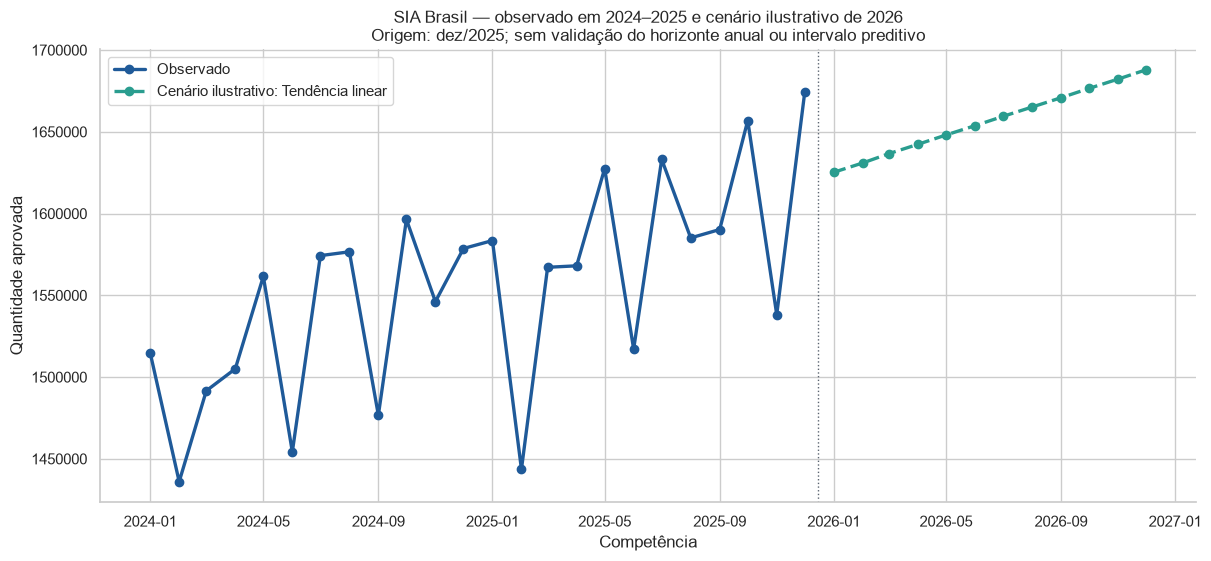

In [18]:
if melhor_modelo == 'Média móvel (3 meses)':
    previsao_2026 = previsao_media_movel(serie_completa, 12)
elif melhor_modelo == 'Tendência linear':
    previsao_2026 = previsao_tendencia_linear(serie_completa, 12)
else:
    previsao_2026 = previsao_sazonal_ingenua(serie_completa, 12)

futuro = pd.DataFrame({'data': pd.date_range('2026-01-01', periods=12, freq='MS'), 'previsao_sia': previsao_2026})
display(futuro.assign(mes=lambda x: x['data'].dt.strftime('%m/%Y')).loc[:, ['mes', 'previsao_sia']].style.format({'previsao_sia': '{:,.0f}'}))

fig, ax = plt.subplots(figsize=(12, 5.5), layout='constrained')
ax.plot(sia_mensal['data'], sia_mensal['sia'], color=CORES['sia'], marker='o', linewidth=2.4, label='Observado')
ax.plot(futuro['data'], futuro['previsao_sia'], color=CORES['destaque'], marker='o', linestyle='--', linewidth=2.4, label=f'Cenário ilustrativo: {melhor_modelo}')
ax.axvline(pd.Timestamp('2025-12-15'), color=CORES['cinza'], linestyle=':', linewidth=1)
ax.set(title='SIA Brasil — observado em 2024–2025 e cenário ilustrativo de 2026\nOrigem: dez/2025; sem validação do horizonte anual ou intervalo preditivo', xlabel='Competência', ylabel='Quantidade aprovada')
ax.ticklabel_format(axis='y', style='plain')
ax.legend(frameon=True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

<a id="secao-10"></a>

## 10. Discussão dos resultados, conclusão e limitações

Na janela janeiro–outubro, SIA cresceu 3,85% e SIH N17–N19 cresceu 4,04% em 2025 frente a 2024. Houve aumento SIA em 25/27 UFs (92,6%; IC exato de referência: 75,7%–99,1%) e SIH em 17/27 (63,0%; 42,4%–80,6%). Os intervalos são condicionados ao modelo binomial; não representam erro amostral de um censo territorial.

Na família de três testes deste caderno, sinais SIA apresentou p-Holm ≈ 0,000017; sinais SIH, p-Holm ≈ 0,427. A correlação entre variações foi ρ = −0,247 (p bruto ≈ 0,214; p-Holm ≈ 0,427). Há evidência exploratória de predomínio de aumento SIA; não há evidência suficiente de mudança direcional SIH ou de associação monotônica entre variações. Isso não demonstra estabilidade ou independência.

Levene indicou heterogeneidade regional (p=0,037). Kruskal–Wallis (p=0,248) não identificou evidência suficiente de diferença entre distribuições regionais; grupos pequenos e dispersões distintas limitam a interpretação. Não se conclui igualdade de regiões ou medianas.

A sensibilidade imputou 27 internações para RR/dezembro de 2025 (fator jan–out: 0,704), sem alterar resultados principais. Ela não resolve a possível incompletude SIH em novembro/dezembro.

A tendência linear apresentou menor MAPE (3,01%), MAE de 46.849 e RMSE de 62.453 unidades de quantidade aprovada. Essas métricas avaliam previsões de um mês à frente em 2025 e não garantem precisão para o cenário de 12 meses de 2026. Não houve conjunto final independente após a seleção.

**Conclusão:** os resultados descrevem registros territoriais e não estimam pacientes, acesso, prevalência, efetividade ou causalidade. N17–N19 inclui insuficiência renal aguda, crônica e não especificada; não é indicador específico de DRC. APAC e N18 seguem fora da análise principal.

**Entrega concluída:** gráficos revisados, relatório acadêmico consolidado e versão final executada/salva em kernel Jupyter, com registro do ambiente e SHA-256 da base. Consulte `../relatorio_final_analise_estatistica_drc_2024_2025.md` e o registro de fechamento para as evidências. O detalhamento está nas seções 11 e 12 do plano. Novas extrações SIH/SIA e eventual reabertura APAC/N18 são possibilidades de pesquisa futura, fora dos critérios de conclusão desta entrega.


**Resposta final com os dados disponíveis:** o volume nacional cresceu em janeiro–outubro (SIA: +585.014; SIH: +5.284). O aumento SIA foi disseminado em 25 UFs, enquanto o SIH apresentou maior heterogeneidade direcional. Rankings, variações absolutas/percentuais e produção SIA por população descrevem os contrastes territoriais observados. Não se identificou evidência suficiente de associação entre as variações SIA/SIH ou de diferença regional da variação SIA. A comparação retrospectiva favoreceu a tendência linear entre os três candidatos, no horizonte de um mês.

**Decisão de fechamento:** novembro/dezembro SIH ficam fora das comparações principais desta versão, sem aguardar confirmação externa. O cenário de 2026 é uma extrapolação ilustrativa a partir de dezembro de 2025, não uma previsão atualizada na data de redação. Há 27 UFs nos testes e 24 totais mensais na previsão; as 648 linhas do painel não representam observações independentes para essas análises. Não são necessários novos testes ou modelos para concluir essas respostas.


### Síntese dos padrões exploratórios — evidência, método e limites

Todos os valores de mudança territorial e concentração abaixo usam **janeiro–outubro de 2025 versus 2024**. As taxas SIA usam **janeiro–dezembro** e população anual; SIA é quantidade aprovada e SIH é número de internações N17–N19. As tabelas `exploracao_*.csv` da entrega reproduzem os cálculos da seção 6.4.

| Pergunta e padrão observado | Evidência numérica e apoio gráfico | Método e interpretação | Limitação |
|---|---|---|---|
| O nível mensal aumentou de modo uniforme? | SIA: 11/12 meses homólogos positivos; setembro +7,69%, novembro −0,51%. SIH: 9/10 positivos; agosto +8,56%, outubro −3,82%. Tabela `exploracao_mensal.csv`; série Brasil da seção 6.2. | Razão entre totais do mesmo mês; crescimento disseminado no calendário, com exceções. Não é crescimento monotônico mês a mês. | Revisões administrativas continuam possíveis; SIH nov/dez excluído. |
| Há oscilação recorrente? | Fevereiro é o mínimo nos dois anos e indicadores. SIA: 1.436.017 em 2024 e 1.443.598 em 2025; SIH: 12.204 e 12.750 na janela jan–out. CV mensal SIA: 3,52% e 4,03%; SIH: 3,36% e 3,75%. | Extremos e desvio-padrão amostral/média × 100; amplitude SIA passa de 160.353 a 230.857 unidades. | Dois ciclos, número de dias e calendário de atendimento impedem afirmar sazonalidade estável. CV mistura tendência e oscilação; não estima volatilidade residual. |
| Crescimento e intensidade populacional dão o mesmo ranking? | Norte: SIA +9,36%; Centro-Oeste +1,57%. Sudeste acrescenta 241.364 unidades (1,59 ponto percentual do crescimento nacional); Nordeste, 208.050 (1,37 pp). Taxa SIA anual 2025: Nordeste 10.060,9 e Norte 6.259,8 por 100 mil. | Razão das somas por região e contribuição = diferença regional/total Brasil 2024 × 100. Crescimento relativo maior pode coexistir com menor intensidade bruta por população. | Comparação de crescimento usa dez meses; taxa usa doze. Sem padronização etária, fluxos ou medida de necessidade assistencial. Kruskal–Wallis p=0,248 não demonstra igualdade. |
| O volume está concentrado? | Cinco maiores UFs SIA: SP, MG, BA, RJ e PE; 54,97% em 2024 e 55,00% em 2025. SIH: 57,12% e 56,62%, com PR substituindo RS no grupo. SP acrescenta 112.885 unidades SIA e 1.428 internações. | Participação na soma nacional e ranking por volume, recalculado em cada ano; concentração SIA semelhante nos dois períodos. | Participação de produção no local de atendimento não mede concentração de pacientes residentes ou desigualdade de acesso. |
| Os extremos percentuais dominam o aumento nacional? | Cercas IQR SIA: −4,34% a +11,61%; extremos AC +14,30%, PA +12,09%, TO +22,49%. TO: 69.798 → 85.498 (+15.700), contribuição 0,10 pp; SP: +3,39%, mas +112.885 e 0,74 pp. Taxa anual 2025: TO 6.441,6 versus SP 8.988,8 por 100 mil. | Cercas de 1,5 IQR sinalizam valores para leitura conjunta com base absoluta e taxa anual. Não há exclusão de UFs. | Extremo estatístico não é erro nem desempenho assistencial; denominadores menores amplificam percentuais. |
| Há extremos SIH mesmo na janela escolhida? | Cercas SIH: −22,15% a +27,65%; AP 305 → 416 (+111; +36,39%); RR 500 → 352 (−148; −29,60%). | Mesmo critério IQR sobre as 27 variações; a heterogeneidade não se resume aos meses finais excluídos. | A janela selecionada não elimina possíveis diferenças de registro; não atribuir causas. |
| Como as direções conjuntas se organizam? | 15 UFs aumentam ambos (55,56%); dez aumentam SIA e reduzem SIH (37,04%); duas reduzem SIA e aumentam SIH (7,41%: AM e DF); nenhuma reduz ambos ou empata. | Nove categorias exclusivas, incluindo empates, totalizam 27. Os 12 casos divergentes são 44,44%. A tabela articula as probabilidades marginais (25/27 e 17/27) e a interseção (15/27). | Categorias de sinais não descrevem a ordenação das magnitudes; Spearman ρ=−0,247 e p-Holm=0,427 continua sem evidência suficiente de associação monotônica. Não demonstra independência ou proteção. |

**Perguntas sem resposta suficiente:** não é possível confirmar sazonalidade persistente, explicar a causa dos extremos, demonstrar igualdade regional, inferir efeito da hemodiálise sobre internações ou validar o cenário anual de 2026. A comparação preditiva de um mês à frente sustenta apenas o desempenho retrospectivo descrito na seção 9. Nenhum novo teste foi acrescentado.

**Discussão e conclusão ampliadas:** o crescimento nacional combina disseminação territorial, concentração de volumes e ritmos regionais distintos. O avanço relativo do Norte coexiste com a menor produção anual SIA por população; os maiores percentuais estaduais não coincidem necessariamente com as maiores contribuições absolutas. A oscilação mensal e as 12 direções territoriais divergentes qualificam a leitura do crescimento agregado. Esses padrões descrevem a extração observada e geram hipóteses, sem confirmar mecanismos clínicos, acesso ou causalidade.


<a id="secao-11"></a>

## 11. Registro de reprodutibilidade e exportação da entrega

Esta célula identifica a base por SHA-256, registra o ambiente do kernel e exporta somente tabelas derivadas e metadados. O painel e as fontes originais permanecem preservados. Os CSVs usam ponto decimal e separador `;`. A data de execução real é registrada com fuso de São Paulo; a data editorial da entrega é 15/11/2026.

**Método de documentação:** identificação da entrada por hash, registro das versões e exportação das tabelas derivadas. Esta seção sustenta a reprodução do trabalho; não constitui uma nova análise inferencial.

In [19]:
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime
from zoneinfo import ZoneInfo

pasta_entrega = projeto / 'Dados/03_bases_analiticas/analise_estatistica_final_2024_2025'
pasta_entrega.mkdir(parents=True, exist_ok=True)

registro_execucao = {
    'data_execucao': datetime.now(ZoneInfo('America/Sao_Paulo')).isoformat(),
    'data_editorial': '2026-11-15',
    'base': arquivo_base.relative_to(projeto).as_posix(),
    'sha256_base': hashlib.sha256(arquivo_base.read_bytes()).hexdigest(),
    'python': platform.python_version(),
    'pacotes': {nome: importlib.metadata.version(nome) for nome in
                ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'seaborn',
                 'ipykernel', 'nbclient', 'nbformat']},
    'linhas': len(painel),
    'ufs': int(painel['sigla_uf'].nunique()),
    'competencias': int(painel['competencia'].nunique()),
    'ausencias_sih': int(painel['sih_n17_n19_internacoes_tabnet'].isna().sum()),
    'janela_principal': 'janeiro–outubro de 2024 e 2025',
    'familia_holm': ['sinais SIA', 'sinais SIH', 'Spearman das variacoes'],
    'horizonte_validado_meses': 1,
    'previsoes_validacao': len(observados_validacao),
}

for nome, tabela in {
    'exploracao_mensal': mensal_exploratorio,
    'exploracao_resumo_temporal': resumo_temporal,
    'exploracao_territorial': territorios_exploratorios,
    'exploracao_regional': regional_exploratorio,
    'exploracao_concentracao': concentracao,
    'exploracao_mudancas_conjuntas': mudancas_conjuntas,
    'exploracao_direcoes_uf': conjunta_ufs,
    'resumo_numerico': resumo.reset_index(),
    'cobertura_sih': cobertura,
    'comparacao_uf_jan_out': comparacao,
    'taxa_sia_anual_uf': sia_anual_uf,
    'taxa_sia_anual_regiao': taxa_sia_regional,
    'probabilidades_basicas': estudo_probabilidades,
    'probabilidades': probabilidades.rename_axis('indicador').reset_index(),
    'inferencias_familia_3': inferencias,
    'metricas_validacao': metricas,
    'cenario_ilustrativo_2026': futuro,
}.items():
    tabela.to_csv(pasta_entrega / f'{nome}.csv', sep=';', index=False, encoding='utf-8')
(pasta_entrega / 'registro_execucao.json').write_text(
    json.dumps(registro_execucao, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
display(pd.DataFrame([{'campo': chave, 'valor': str(valor)}
                      for chave, valor in registro_execucao.items() if chave != 'pacotes']))
display(pd.Series(registro_execucao['pacotes'], name='versao').to_frame())
print('Tabelas derivadas e registro salvos em:', pasta_entrega.relative_to(projeto))

,campo,valor
0,data_execucao,2026-11-15T20:33:07.653960-03:00
1,data_editorial,2026-11-15
2,base,Dados/03_bases_analiticas/descritiva_territori...
3,sha256_base,5d8f671d31c7b83aa4e1e20c1221731e941957ed32e6f7...
4,python,3.12.13
5,linhas,648
6,ufs,27
7,competencias,24
8,ausencias_sih,1
9,janela_principal,janeiro–outubro de 2024 e 2025


,versao
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
statsmodels,0.15.0
matplotlib,3.11.2
seaborn,0.13.2
ipykernel,7.4.0
nbclient,0.11.0
nbformat,5.11.1


Tabelas derivadas e registro salvos em: Dados/03_bases_analiticas/analise_estatistica_final_2024_2025


<a id="secao-12"></a>

## 12. Referências bibliográficas e fontes dos dados

A bibliografia completa deste trabalho, com os documentos consultados, endereços das fontes, datas de acesso e explicação de seu uso no estudo, está disponível em:

**[Consultar as referências bibliográficas do projeto](../referencias_bibliograficas_doenca_renal_cronica_sus.md)**

As principais fontes de dados são:

- **Ministério da Saúde — DATASUS / SIA/SUS:** produção ambulatorial aprovada de procedimentos de hemodiálise.
- **Ministério da Saúde — DATASUS / SIH/TabNet:** internações na categoria insuficiência renal N17–N19.
- **Instituto Brasileiro de Geografia e Estatística — IBGE:** estimativas anuais da população das UFs, com referência em julho de 2024 e de 2025.

As referências do projeto incluem também documentação de fontes auditadas ou complementares; sua presença na bibliografia não significa inclusão na análise principal. Este notebook utiliza o painel SIA/SIH/IBGE definido na metodologia.

[Voltar ao início do trabalho](#topo)
